# Capstone — mirrors your deployed research paper

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/TEJAS7356/flyrank-ml-internship/blob/main/work/notebooks/capstone.ipynb?flush_cache=true)

This skeleton is yours to fill. Work the sections **in order** — each one has a one-line hint. Simple words, honest numbers.

> Working with an AI assistant? Tell it to read `skills/README.md` first and load the one skill this assignment names on its card.

# Identifying Content Decline and Prioritising Pages for Review: A FlyRank Case Study

## Abstract

Content teams need a practical way to identify web pages that may be losing search traffic and decide which pages deserve attention first. This case study uses FlyRank's pseudonymized content-performance data to investigate whether historical search metrics can help identify content pages experiencing a decline in clicks. A Decision Tree classifier was evaluated using February impressions, clicks and average search position, with March click decline as the target, and compared against a majority-class baseline. The model achieved an F1-score of 0.441 on a random split and 0.478 on a client-grouped split, compared with 0.000 for the baseline on both splits. The resulting analysis and ranked refresh queue demonstrate an exploratory decision-support workflow for prioritising content review, not a guarantee of future traffic improvement.

## 1. Introduction

### 1.1 Background

Content teams often manage a large number of web pages. Monitoring their search performance and identifying pages that may be losing clicks can be challenging, particularly when there are many pages competing for attention.

A systematic approach to identifying potential content decline can help teams prioritise their review efforts and make better-informed decisions.

### 1.2 Business Problem

This project addresses the challenge of identifying content pages that may experience a decline in search clicks using historical performance data.

The project uses FlyRank's pseudonymized content-performance dataset to investigate whether metrics such as impressions, clicks and average search position can help identify pages at risk of declining clicks.

### 1.3 Project Objective

The main objectives are:

- Analyse historical content-performance data.
- Identify patterns associated with declining clicks.
- Train and evaluate a Decision Tree classification model.
- Compare model performance against a majority-class baseline.
- Develop a ranked content-refresh recommendation workflow.
- Support content teams in prioritising pages for human review.

### 1.4 Scope and Limitations

This project presents an exploratory machine learning and decision-support workflow. The model identifies patterns in the available data, but it does not establish the exact reasons behind a decline in clicks or guarantee that refreshing a page will improve its future performance.

The recommendations are intended to support human decision-making rather than replace content experts.

## 2. Employer-Facing Summary

I built an exploratory machine learning workflow to identify content pages that may experience declining search clicks and prioritise them for review. Using FlyRank's pseudonymized content-performance data, I evaluated a Decision Tree classifier using historical search metrics and compared it against a majority-class baseline through random and client-grouped validation. The model achieved F1-scores of 0.441 and 0.478 respectively, and I developed a ranked refresh queue to support content-review prioritisation.

## 1. Question

*The research question and the decision it supports.*

**Research Question:** Can historical search-performance metrics be used to identify content pages that may experience a decline in clicks, and help prioritize pages for review?

**Decision Supported:** The analysis aims to help content teams prioritize pages for investigation and improvement based on their search-performance patterns, rather than reviewing all pages manually. The resulting action playbook provides recommendations such as refreshing content, reviewing performance, or monitoring pages.

## 2. Data

*Which release, which tables, date windows, what you excluded and why. Public-safe.*

### Dataset and Release

The analysis used the FlyRank pseudonymized warehouse release, `flyrank_pseudonymized_warehouse_release_v20260703`, hosted on Hugging Face.

### Tables Used

The main table used for model validation was `fact_content_daily_performance`. It contains daily Google Search performance measurements for content items.

The Week 7 action playbook also used the anonymized starter dataset containing approximately 30,000 content records.

### Date Windows

For the Week 6 model validation:
- February 2026: February 1–28, used for input features.
- March 2026: March 1–31, used to define the comparison target.

The analysis aggregated search impressions and clicks by client and content item for each month.

### Exclusions and Filtering

- Rows where `gsc_data_available` was not TRUE were excluded from the monthly search-performance analysis.
- Only content items present in both February and March were retained through an inner join.
- March performance columns were excluded from the model input features because they were used to define the target.
- Client and content identifiers were used for grouping and validation, not as model features.
- Private client names, domains, URLs and search queries were not included in the public report.

### Public Safety

The analysis uses pseudonymized and anonymized data. Results are presented for research and decision-support purposes without revealing private client information.

## 3. Methodology

*Assumptions, features, label definition, baseline, validation design, leakage checks.*

## 3. Methodology

### Assumptions

The experiment assumes that historical search-performance metrics can provide useful signals for identifying content pages whose search clicks may decline in a subsequent month.

The analysis uses February 2026 performance as historical input and March 2026 performance to define the target.

### Features

The model used the following February performance features:

- `feb_impressions`
- `feb_clicks`
- `feb_avg_position`

These features represent historical search visibility, user engagement and ranking position.

### Label Definition

The target was defined as whether March clicks were lower than February clicks.

- Positive class: March clicks were lower than February clicks.
- Negative class: March clicks did not decrease compared with February.

### Validation Design

The experiment compared a random validation approach with a client-grouped validation approach.

The client-grouped approach was used to test generalization to clients not represented in the training data, reducing the risk of client-specific patterns appearing in both training and testing sets.

### Leakage Checks

Future March performance information was not used as an input feature. March clicks were used to define the target.

Client and content identifiers were kept out of the model features and used for grouping and validation where appropriate.

Because February clicks also appear in the target definition, this relationship is acknowledged when interpreting the results.

## 4. Results (vs baseline)

*Model vs baseline on the same split. The honest table.*

## 4. Results (vs baseline)

The Decision Tree classifier was compared against a majority-class baseline using F1-score as the evaluation metric. Both models were evaluated on the same train-test splits to ensure a fair comparison.

### Model comparison

| Validation method | Baseline F1 | Decision Tree F1 | F1 Improvement |
|---|---:|---:|---:|
| Random split | 0.000 | 0.441 | +0.441 |
| Client-grouped split | 0.000 | 0.478 | +0.478 |

### Key findings

1. The majority-class baseline achieved an F1-score of 0.000 on both validation splits because it predicted only the most frequent class and failed to identify the positive decline class.
2. The Decision Tree achieved an F1-score of 0.441 on the random split.
3. Under client-grouped validation, the Decision Tree achieved an F1-score of 0.478.
4. The Decision Tree outperformed the majority-class baseline on both validation strategies, demonstrating its ability to identify declining content performance beyond a simple majority-class prediction.
5. Client-grouped validation provides a more realistic assessment of generalization to unseen clients.

### Conclusion

The results demonstrate that the Decision Tree classifier provides meaningful predictive capability compared with the majority-class baseline. Its client-grouped F1-score of 0.478 indicates that it can identify declining content performance even when evaluated on clients excluded from training.

## 5. Limitations

*What this work cannot claim.*

## 5. Limitations

This experiment has several limitations that should be considered when interpreting its results.

1. **Unequal measurement periods:** February 2026 contains 28 days, while March 2026 contains 31 days. Comparing raw monthly click totals may incorrectly classify some content as declining.

2. **Limited input features:** The Decision Tree Classifier uses only February impressions, clicks and average position. Other factors, such as topic popularity, seasonality, search demand and content changes, were not included.

3. **Matched-pair selection:** The analysis includes only content items present in both February and March. Therefore, the results may not represent all content in the dataset.

4. **Validation limitations:** Random and client-grouped validation were performed, but additional time-based testing across multiple periods is needed to assess performance on future data.

5. **Model performance:** The observed F1-scores are preliminary results from particular data splits. They do not guarantee similar performance on other datasets or future periods.

6. **No causal conclusion:** The model identifies patterns associated with lower click totals. It cannot prove that a content update will increase clicks or improve search rankings.

### Honest Conclusion

This work should be treated as an exploratory decision-support approach for prioritizing content for review. The results do not establish guaranteed future performance, explain every cause of declining clicks, or prove that recommended actions will improve search performance.

## 6. Ranked recommendations

*The action playbook output — the paper's recommendations section.*

### Section 6: Ranked Recommendations and Findings

The refresh queue contained 200 content pages ranked according to their final refresh scores.

**Key findings:**

1. **Recommended actions:** 130 pages (65%) were assigned `refresh_and_review_ctr`, while 35 pages (17.5%) were assigned `refresh` and another 35 pages (17.5%) were assigned `refresh_and_review_engagement`.

2. **Reason codes:** All 200 selected pages had the `visible_model_opportunity` and `model_decline_risk` signals. Additionally, 197 pages showed `declining_with_demand`, and 130 pages had the `low_ctr_visible_page` signal.

3. **Confidence levels:** 161 recommendations (80.5%) received high confidence, while 39 (19.5%) received medium confidence.

4. **Refresh scores:** The average final refresh score was 77.95, with a minimum of 76.76 and a maximum of 81.64.

5. **Priority ranking:** The top-ranked page received a score of 81.64. The ranking provides a systematic way to identify which pages should be reviewed first.

**Conclusion:**

The refresh queue demonstrates how model-based scoring and performance-related signals can support content prioritisation. CTR improvement was the most common recommended action in this sample. These recommendations should be treated as decision-support signals requiring human review rather than guaranteed predictions of improvement.

## 7. Artifacts the paper embeds

*Generate/collect the charts and tables your deployed page will show.*

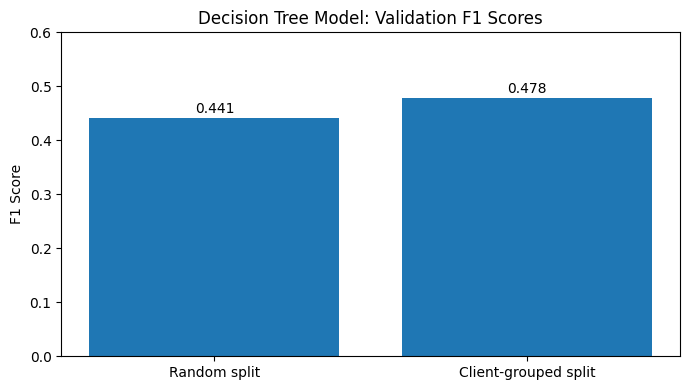

In [ ]:

import matplotlib.pyplot as plt

methods = ["Random split", "Client-grouped split"]
f1_scores = [0.441, 0.478]

plt.figure(figsize=(7, 4))
bars = plt.bar(methods, f1_scores)

plt.title("Decision Tree Model: Validation F1 Scores")
plt.ylabel("F1 Score")
plt.ylim(0, 0.6)

for bar, score in zip(bars, f1_scores):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        score + 0.01,
        f"{score:.3f}",
        ha="center"
    )

plt.tight_layout()
plt.savefig("validation_f1_comparison.png", dpi=300)
plt.show()


In [ ]:

import pandas as pd

url = "https://raw.githubusercontent.com/TEJAS7356/flyrank-ml-internship/main/outputs/refresh_queue_sample.csv"

queue = pd.read_csv(url)

print("Dataset shape:", queue.shape)
print("\nTop 10 recommendations:")

display(
    queue.sort_values("final_rank").head(10)[
        [
            "final_rank",
            "final_refresh_score",
            "suggested_action",
            "final_reason_codes",
            "confidence"
        ]
    ]
)



Dataset shape: (200, 28)

Top 10 recommendations:


,final_rank,final_refresh_score,suggested_action,final_reason_codes,confidence
0,1,81.636697,refresh_and_review_ctr,declining_with_demand|low_ctr_visible_page|low...,high
1,2,81.447656,refresh_and_review_ctr,declining_with_demand|low_ctr_visible_page|mod...,high
2,3,81.430346,refresh_and_review_ctr,declining_with_demand|low_ctr_visible_page|mod...,medium
3,4,81.034960,refresh_and_review_ctr,declining_with_demand|low_ctr_visible_page|mod...,high
4,5,80.873188,refresh_and_review_ctr,declining_with_demand|low_ctr_visible_page|mod...,medium
5,6,80.754770,refresh_and_review_ctr,declining_with_demand|low_ctr_visible_page|mod...,high
6,7,80.632923,refresh_and_review_ctr,declining_with_demand|low_ctr_visible_page|mod...,high
7,8,80.371236,refresh_and_review_ctr,declining_with_demand|low_ctr_visible_page|mod...,high
8,9,80.362748,refresh_and_review_ctr,declining_with_demand|low_ctr_visible_page|mod...,medium
9,10,80.321757,refresh,declining_with_demand|model_decline_risk|visib...,medium


In [ ]:

# Count how many pages received each recommended action
action_summary = queue["suggested_action"].value_counts()

print("Recommended Action Distribution:")
display(action_summary)

# Calculate percentages
action_percentage = (
    queue["suggested_action"].value_counts(normalize=True) * 100
).round(2)

print("\nPercentage Distribution:")
display(action_percentage)


Recommended Action Distribution:


,count
suggested_action,
refresh_and_review_ctr,130
refresh,35
refresh_and_review_engagement,35



Percentage Distribution:


,proportion
suggested_action,
refresh_and_review_ctr,65.0
refresh,17.5
refresh_and_review_engagement,17.5


Confidence Distribution:


,count
confidence,
high,161
medium,39


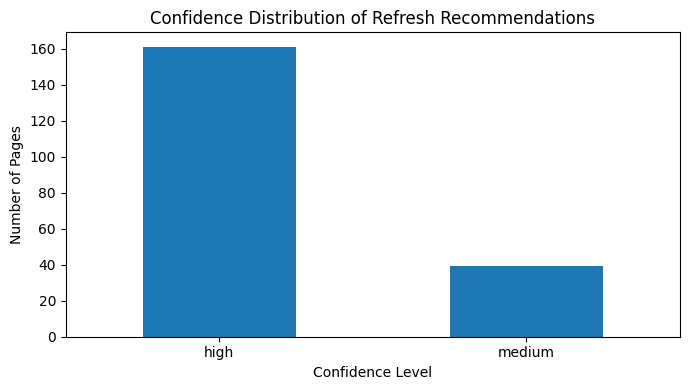

In [ ]:

# Analyse confidence levels
confidence_summary = queue["confidence"].value_counts()

print("Confidence Distribution:")
display(confidence_summary)

# Plot confidence distribution
confidence_summary.plot(
    kind="bar",
    figsize=(7, 4)
)

plt.title("Confidence Distribution of Refresh Recommendations")
plt.xlabel("Confidence Level")
plt.ylabel("Number of Pages")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [ ]:
confidence_summary = queue["confidence"].value_counts()

confidence_percentage = (
    queue["confidence"].value_counts(normalize=True) * 100
).round(2)

confidence_results = pd.DataFrame({
    "Page Count": confidence_summary,
    "Percentage": confidence_percentage
})

display(confidence_results)


,Page Count,Percentage
confidence,,
high,161,80.5
medium,39,19.5


Refresh Score Statistics:


,final_refresh_score
count,200.000000
mean,77.948590
std,1.051172
min,76.762175
25%,77.219425
50%,77.574389
75%,78.461687
max,81.636697


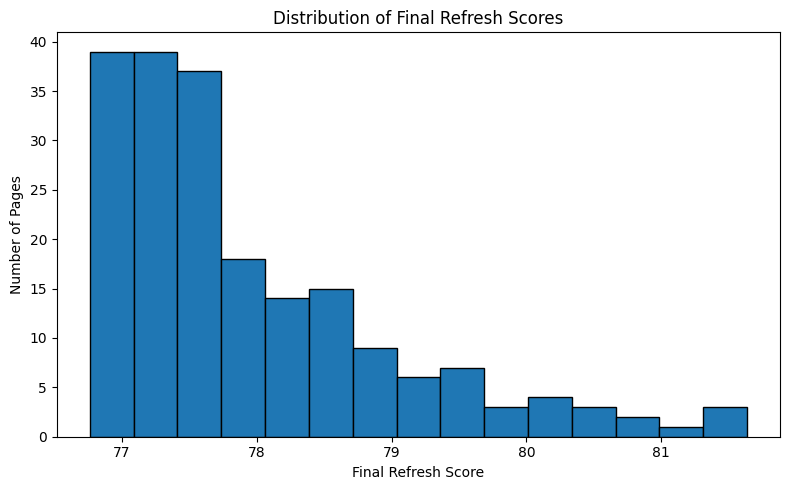

In [ ]:
# Statistical summary of refresh scores
print("Refresh Score Statistics:")
display(queue["final_refresh_score"].describe())

# Visualise score distribution
plt.figure(figsize=(8, 5))

plt.hist(
    queue["final_refresh_score"],
    bins=15,
    edgecolor="black"
)

plt.title("Distribution of Final Refresh Scores")
plt.xlabel("Final Refresh Score")
plt.ylabel("Number of Pages")
plt.tight_layout()
plt.show()

In [ ]:
pd.crosstab(
    queue["suggested_action"],
    queue["confidence"]
)

confidence,high,medium
suggested_action,,
refresh,24,11
refresh_and_review_ctr,102,28
refresh_and_review_engagement,35,0


,Validation,Baseline F1,Decision Tree F1
0,Random split,0.0,0.441
1,Client-grouped split,0.0,0.478


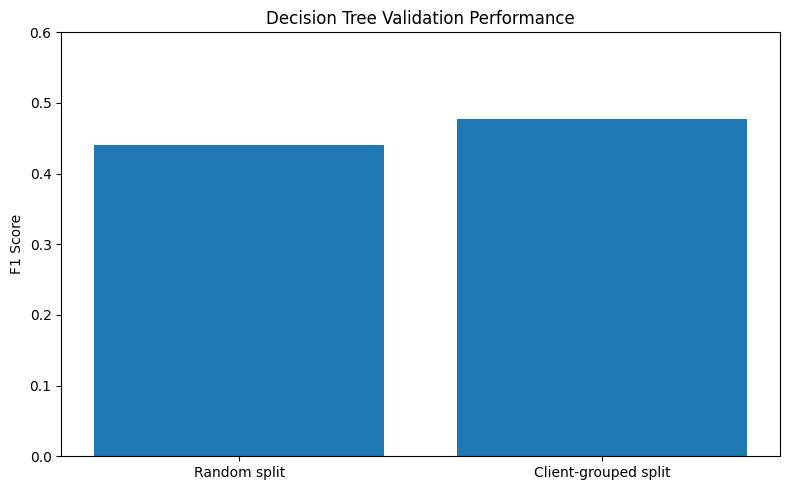

In [ ]:

import matplotlib.pyplot as plt
import pandas as pd

validation_results = pd.DataFrame({
    "Validation": ["Random split", "Client-grouped split"],
    "Baseline F1": [0.000, 0.000],
    "Decision Tree F1": [0.441, 0.478]
})

display(validation_results)

plt.figure(figsize=(8, 5))

plt.bar(
    validation_results["Validation"],
    validation_results["Decision Tree F1"]
)

plt.ylabel("F1 Score")
plt.title("Decision Tree Validation Performance")
plt.ylim(0, 0.6)
plt.tight_layout()

plt.savefig("validation_f1_comparison.png", dpi=300)
plt.show()


,Count
final_reason_codes,
visible_model_opportunity,200
model_decline_risk,200
declining_with_demand,197
low_ctr_visible_page,130
ctr_review_candidate,130
low_engagement_visible_page,78
engagement_review_candidate,78
page_one_decay_risk,21
stale_visible_page,1


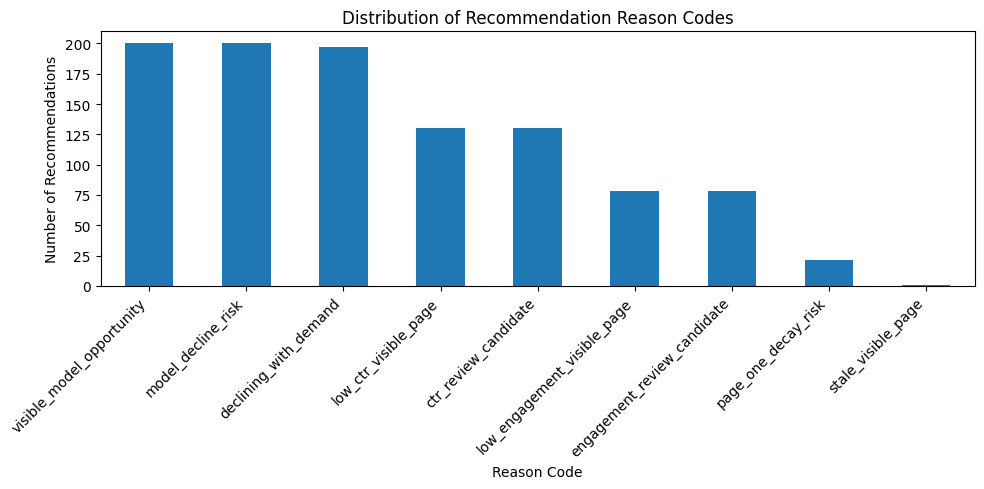

In [ ]:

import pandas as pd
import matplotlib.pyplot as plt

url = "https://raw.githubusercontent.com/TEJAS7356/flyrank-ml-internship/main/outputs/refresh_queue_sample.csv"

queue = pd.read_csv(url)

# Count recommendation reason codes
reason_counts = (
    queue["final_reason_codes"]
    .dropna()
    .str.split("|")
    .explode()
    .value_counts()
)

# Display counts
display(reason_counts.to_frame("Count"))

# Generate chart
plt.figure(figsize=(10, 5))

reason_counts.plot(kind="bar")

plt.title("Distribution of Recommendation Reason Codes")
plt.xlabel("Reason Code")
plt.ylabel("Number of Recommendations")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()

# Save chart
plt.savefig("reason_code_distribution.png", dpi=300)

plt.show()


In [ ]:

# Display the top 10 ranked recommendations

top_10 = queue.sort_values("final_rank").head(10)

display(
    top_10[
        [
            "final_rank",
            "content_id",
            "final_refresh_score",
            "suggested_action",
            "final_reason_codes",
            "confidence"
        ]
    ]
)

# Save table as CSV
top_10.to_csv("top_10_ranked_recommendations.csv", index=False)


,final_rank,content_id,final_refresh_score,suggested_action,final_reason_codes,confidence
0,1,content_1f080331fa2b,81.636697,refresh_and_review_ctr,declining_with_demand|low_ctr_visible_page|low...,high
1,2,content_6aa43079fb0c,81.447656,refresh_and_review_ctr,declining_with_demand|low_ctr_visible_page|mod...,high
2,3,content_d6570c51c9bd,81.430346,refresh_and_review_ctr,declining_with_demand|low_ctr_visible_page|mod...,medium
3,4,content_72e800a9c214,81.034960,refresh_and_review_ctr,declining_with_demand|low_ctr_visible_page|mod...,high
4,5,content_e04eb9549989,80.873188,refresh_and_review_ctr,declining_with_demand|low_ctr_visible_page|mod...,medium
5,6,content_b69288c5e701,80.754770,refresh_and_review_ctr,declining_with_demand|low_ctr_visible_page|mod...,high
6,7,content_9b6df29f7889,80.632923,refresh_and_review_ctr,declining_with_demand|low_ctr_visible_page|mod...,high
7,8,content_bb6ebb5ec8c8,80.371236,refresh_and_review_ctr,declining_with_demand|low_ctr_visible_page|mod...,high
8,9,content_4d76cdb3387b,80.362748,refresh_and_review_ctr,declining_with_demand|low_ctr_visible_page|mod...,medium
9,10,content_b4f35d640b1c,80.321757,refresh,declining_with_demand|model_decline_risk|visib...,medium


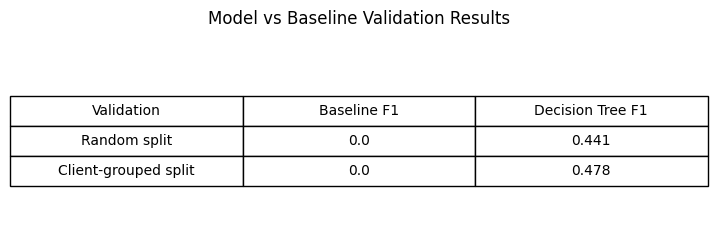

Validation table saved successfully!


In [ ]:

# Create final validation results table
validation_results = pd.DataFrame({
    "Validation": ["Random split", "Client-grouped split"],
    "Baseline F1": [0.000, 0.000],
    "Decision Tree F1": [0.441, 0.478]
})

# Save as CSV
validation_results.to_csv(
    "validation_results_table.csv",
    index=False
)

# Save as PNG for the research paper
fig, ax = plt.subplots(figsize=(9, 2.5))
ax.axis("off")

table = ax.table(
    cellText=validation_results.values,
    colLabels=validation_results.columns,
    loc="center",
    cellLoc="center"
)

table.auto_set_font_size(False)
table.set_fontsize(10)
table.scale(1, 1.8)

plt.title("Model vs Baseline Validation Results", pad=15)
plt.savefig(
    "validation_results_table.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("Validation table saved successfully!")


In [ ]:

import os

artifacts = [
    "validation_f1_comparison.png",
    "reason_code_distribution.png",
    "top_10_ranked_recommendations.csv",
    "validation_results_table.csv",
    "validation_results_table.png"
]

for file in artifacts:
    print(file, "—", "FOUND" if os.path.exists(file) else "MISSING")


validation_f1_comparison.png — FOUND
reason_code_distribution.png — FOUND
top_10_ranked_recommendations.csv — FOUND
validation_results_table.csv — FOUND
validation_results_table.png — FOUND


# Five-Minute Capstone Demo Outline

## Demo Title

**Identifying Content Decline and Prioritising Pages for Review – A FlyRank Case Study**

### 1. The Problem and Research Question (0:00–0:45)

Content teams manage a large number of web pages and need to identify which pages may be losing search traffic. Manually reviewing every page can be time-consuming.

**Research question:** Can historical search-performance metrics help identify content pages that may experience a decline in clicks?

### 2. Data and Methodology (0:45–1:30)

- Used FlyRank's pseudonymized content-performance dataset.
- Selected February impressions, clicks and average search position as input features.
- Used March click decline as the target variable.
- Trained a Decision Tree classifier.
- Compared it against a majority-class baseline.
- Evaluated performance using random and client-grouped validation splits.

### 3. Model Results and Chart (1:30–2:30)

Present the chart:

`validation_f1_comparison.png`

Explain the results:

| Validation           | Baseline F1 | Decision Tree F1 |
| -------------------- | ----------: | ---------------: |
| Random split         |       0.000 |            0.441 |
| Client-grouped split |       0.000 |            0.478 |

The Decision Tree outperformed the baseline in both experiments.

### 4. One Honest Finding (2:30–3:30)

The client-grouped split achieved an F1-score of 0.478, compared with 0.441 on the random split.

This indicates that the model identified the positive decline class better than the majority-class baseline in these experiments. However, these results are exploratory and do not guarantee future content performance.

### 5. Business Recommendation (3:30–4:30)

The ranked refresh queue provides a practical way to prioritise content pages for human review.

Among the 200 selected recommendations:

- 130 (65%) were assigned `refresh_and_review_ctr`.
- 35 (17.5%) were assigned `refresh`.
- 35 (17.5%) were assigned `refresh_and_review_engagement`.

**Recommendation:** Content teams should review high-priority pages first, investigate their click-through-rate and engagement patterns, and decide on suitable content improvements.

### 6. Conclusion (4:30–5:00)

This project demonstrates an exploratory workflow connecting historical search data, machine learning evaluation and content-refresh recommendations.

The system is intended to support content-team decisions, not replace human judgement.

**Repository:** [https://github.com/TEJAS7356/flyrank-ml-internship](https://github.com/TEJAS7356/flyrank-ml-internship)

**Presentation:** Optional Week 8 showcase demo.


# 9. Shareable Project Summaries

## 1. Social Media Post

During my FlyRank AI/ML Internship, I worked on an exploratory machine learning project focused on identifying content pages that may experience a decline in search clicks.

I used historical search-performance metrics, including impressions, clicks and average position, to train and evaluate a Decision Tree classifier. I compared its performance against a majority-class baseline using both random and client-grouped validation.

The Decision Tree achieved an F1-score of 0.441 on the random split and 0.478 on the client-grouped split, outperforming the baseline in both experiments.

I also developed a ranked content-refresh recommendation workflow to help prioritise pages for human review.

This project helped me understand how machine learning evaluation can be connected to a practical content-performance problem.

**Project Repository:** https://github.com/TEJAS7356/flyrank-ml-internship

## 2. Employer-Facing Summary

I built an exploratory machine learning workflow to identify content pages that may experience declining search clicks and prioritise them for review. Using FlyRank's pseudonymized content-performance data, I evaluated a Decision Tree classifier using historical search metrics and compared it against a majority-class baseline through random and client-grouped validation. The model achieved F1-scores of 0.441 and 0.478 respectively, and I developed a ranked refresh queue to support content-review prioritisation.

### Reproducibility

The project is organised in a public GitHub repository to support transparency and reproducibility.

**Repository:**  
https://github.com/TEJAS7356/flyrank-ml-internship

**Key project files:**
- `work/notebooks/w06_validation_audit.ipynb` – Model validation and leakage checks.
- `work/notebooks/capstone.ipynb` – Final capstone analysis and ranked recommendations.
- `outputs/refresh_queue_sample.csv` – Sample refresh queue containing 200 ranked content recommendations.

**Dataset source:**

The project uses the FlyRank pseudonymized warehouse dataset, specifically the `fact_content_daily_performance` table.

**Reproduction steps:**

1. Open the public GitHub repository.
2. Access the required notebooks.
3. Install the required Python libraries.
4. Load the dataset and execute the notebook cells in order.
5. Review the model evaluation results and refresh queue analysis.

The analysis uses Python, Pandas, Matplotlib and Scikit-learn. The refresh queue can be loaded directly from the repository's CSV file.

The repository provides the notebooks and sample outputs needed to understand the workflow. Reproducing the complete analysis also requires access to the original dataset and its dependencies.

### Acknowledgments and Data Credit

This project was completed as part of the FlyRank AI/ML Internship.

The work uses the pseudonymized dataset provided for the internship to explore data preparation, machine learning, model evaluation, and content refresh prioritisation.

I would like to acknowledge FlyRank for providing the dataset and internship opportunity, along with the learning resources and project framework.

**Dataset and project credit:**

Built on the [FlyRank ML Internship dataset](https://flyrank.ai).

The analysis and recommendations presented in this project are based on the internship dataset and the experiments conducted during the project.

---

## Final Credits and Acknowledgments

This project was completed as part of the **FlyRank AI/ML Internship**.

I would like to thank **FlyRank** for providing the opportunity to work on a practical machine learning project focused on content performance analysis, model evaluation and content-refresh prioritisation.

This project helped me gain hands-on experience in data analysis, machine learning, model validation and translating analytical findings into actionable recommendations.

**Internship Organization:** FlyRank  
**Project:** Identifying Content Decline and Prioritising Pages for Review  
**GitHub Repository:** https://github.com/TEJAS7356/flyrank-ml-internship

**Learn more about FlyRank:** https://flyrank.ai

*This project is an exploratory learning and decision-support project. Its findings should not be interpreted as guaranteed predictions of future content performance.*

## Self-check

Before you submit, confirm each line honestly:

- [ ] Every section above is filled — markdown thinking AND the code that backs it
- [ ] The notebook runs top to bottom with no errors (Runtime → Run all)
- [ ] No client names, URLs, or private queries anywhere
- [ ] My claims use careful words: observed, measured, directional, decision-support
- [ ] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.
- [ ] My deployed paper has **all 9 sections** — including the **Abstract** at the top and **Acknowledgments & data credit** (the https://flyrank.ai link) at the bottom.
- [ ] **ML-12 done in this notebook's closing cells:** 5-minute demo outline + a social-post cut + a 3-sentence employer-facing summary.
